# 09 — Walk-forward: все сделки ежегодного переотбора по порядку

Самый сильный результат исследования — ежегодный переотбор параметров. Каждый календарный год торгуется
конфигурация, выбранная по трём предыдущим годам среди всех 3,47 млн конфигураций этапа 1 (наклон медленной MA
задан заранее: k = 10). Критерий выбора — сглаженная по соседним периодам t-статистика средней сделки на обучении.
Ниже — все сделки этих конфигураций по порядку, год за годом.

* **Excel:** [`research/ma_cross_slope_5m/tables/trade_ledger_walk_forward.xlsx`](../research/ma_cross_slope_5m/tables/trade_ledger_walk_forward.xlsx).
  Листы: «Сводка», «По годам» (конфигурация и результат каждого тестового года со сверкой с исследованием),
  «Все сделки» и по листу на инструмент.
* **CSV:** [`research/ma_cross_slope_5m/tables/trade_ledger_walk_forward.csv`](../research/ma_cross_slope_5m/tables/trade_ledger_walk_forward.csv).

**Как читать.**
* Все сделки здесь вне выборки обучения: конфигурация года выбрана только по прошлым годам.
* Тестовые годы: NG — 2023–2026, BR, GOLD, SILV, PLT, PLD — 2014–2026. 2026 год неполный (по 13 октября).
  У COPPER и WTI истории меньше четырёх лет, walk-forward для них не считался.
* Как и в исследовании, сделка относится к году, в котором закрыта. Поэтому несколько сделок открыты
  конфигурацией года ещё в конце предыдущего года; они отмечены отдельно (колонка «Вход до начала года» в Excel).
* 1 контракт, без комиссий и проскальзывания. Цены — сырые цены контракта, вход и выход по Open свечи после
  сигнала. Сделка через ролл переходит в новый контракт по цене перекрытия.

In [1]:
import pandas as pd
from IPython.display import Image, display

from src.ma_slope import ledger as L
from src.ma_slope.presentation import FIGS, NAMES, table

led = L.load_ledger(L.WF_CSV)
pd.set_option("display.float_format", "{:,.2f}".format)
print(f"Сделок всего: {len(led):,}".replace(",", " "), "| с входом до начала тестового года:",
      int(led["carry_in"].sum()), f"(их PnL {led.loc[led['carry_in'], 'pnl_usd'].sum():+,.2f} $)")

Сделок всего: 35 844 | с входом до начала тестового года: 47 (их PnL +584.59 $)


## Сводка по инструментам

In [2]:
L.summary_table(led)

,сделок,прибыльных,убыточных,доля прибыльных,"итого PnL, $",тестовых лет,лет в плюсе,"средняя сделка, $","средняя сделка, тиков","лучшая, $","худшая, $",макс. убытков подряд,"макс. просадка, $"
NG,1737,530,1189,0.31,874.30,4,4,0.50,5.03,150.50,-54.20,18,146.20
BR (Brent),6140,1799,4132,0.29,881.50,13,9,0.14,1.44,216.20,-182.80,25,646.70
GOLD (GC),3582,1182,2364,0.33,"1,887.50",13,6,0.53,5.27,548.30,-156.20,19,730.50
SILV (SI),3459,1125,2223,0.33,862.30,13,9,0.25,2.49,195.70,-44.70,23,143.80
PLT (PL),13484,5352,7566,0.40,"2,935.00",13,12,0.22,2.18,293.30,-228.00,15,422.50
PLD (PA),7442,2880,4447,0.39,"3,019.06",13,10,0.41,40.57,321.18,-96.35,18,"1,236.76"


## Конфигурация и результат каждого тестового года

«t на обучении» — сглаженная t-статистика выбранной конфигурации за три года обучения. «PnL по исследованию» —
результат того же года из `tables/walk_forward.csv`: ledger воспроизводит его до округления хранения.

In [3]:
wf = table("walk_forward.csv")
wf = wf[(wf["stage"] == "stage1") & (wf["scope"] == "all")].set_index(["ticker", "test_year"])
years = (led.groupby(["ticker", "test_year"], sort=False)
            .agg(конфигурация=("config", "first"), сделок=("pnl_usd", "size"),
                 прибыльных=("pnl_usd", lambda p: int((p > 0).sum())), pnl=("pnl_usd", "sum")))
years["t на обучении"] = wf["train_plateau_t"]
years["PnL по исследованию, $"] = wf["test_pnl"]
years = years.rename(columns={"pnl": "PnL, $"}).rename(index=NAMES, level=0).rename_axis(["инструмент", "год"])
with pd.option_context("display.max_rows", None, "display.max_colwidth", 70):
    display(years)

конфигурация  \
инструмент год                                                                   
NG         2023             SMA21 / EMA66, pct k=10 eps=0.02%, exit=slope_flip   
           2024             SMA21 / EMA66, pct k=10 eps=0.02%, exit=slope_flip   
           2025             SMA21 / EMA68, pct k=10 eps=0.02%, exit=slope_flip   
           2026       SMA92 / EMA85, atr k=10 eps=0.25 atr=14, exit=slope_flip   
BR (Brent) 2014       WMA43 / TMA83, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2015        TMA2 / TMA83, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2016           SSMA73 / WMA247, pct k=10 eps=0.02%, exit=slope_flip   
           2017      VWMA78 / TMA68, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2018           SSMA67 / EMA132, pct k=10 eps=0.02%, exit=slope_flip   
           2019      VWMA10 / VWMA5, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2020   TMA46 / VWMA56, atr k=10 eps=0.25 atr=14, exit=reverse_cross   
           2021            WMA83 / SMA111, pct k=10 eps=0.02%, exit=slope_flip   
           2022            TMA44 / SMA127, pct k=10 eps=0.02%, exit=slope_flip   
           2023      TMA33 / EMA181, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2024      TMA30 / EMA182, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2025            VWMA84 / WMA81, pct k=10 eps=0.02%, exit=slope_flip   
           2026      WMA82 / VWMA47, atr k=10 eps=0.25 atr=14, exit=slope_flip   
GOLD (GC)  2014       EMA66 / SMA55, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2015      VWMA99 / SMA55, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2016      SSMA63 / SMA86, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2017           SSMA65 / VWMA90, pct k=10 eps=0.02%, exit=slope_flip   
           2018          SSMA73 / SSMA228, pct k=10 eps=0.02%, exit=slope_flip   
           2019             EMA83 / EMA98, pct k=10 eps=0.02%, exit=slope_flip   
           2020             TMA91 / EMA37, pct k=10 eps=0.02%, exit=slope_flip   
           2021     SSMA99 / EMA152, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2022            SMA2 / VWMA168, pct k=10 eps=0.02%, exit=slope_flip   
           2023           WMA51 / SSMA250, pct k=10 eps=0.02%, exit=slope_flip   
           2024      VWMA78 / TMA65, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2025           SMA35 / VWMA178, pct k=10 eps=0.02%, exit=slope_flip   
           2026           WMA18 / VWMA164, pct k=10 eps=0.02%, exit=slope_flip   
SILV (SI)  2014             SMA59 / SMA48, pct k=10 eps=0.02%, exit=slope_flip   
           2015             WMA98 / SMA48, pct k=10 eps=0.02%, exit=slope_flip   
           2016     SMA99 / VWMA224, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2017     EMA95 / SSMA220, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2018           SSMA64 / EMA123, pct k=10 eps=0.02%, exit=slope_flip   
           2019             SMA84 / TMA80, pct k=10 eps=0.02%, exit=slope_flip   
           2020           SSMA77 / SMA139, pct k=10 eps=0.02%, exit=slope_flip   
           2021           EMA23 / VWMA131, pct k=10 eps=0.02%, exit=slope_flip   
           2022           EMA28 / VWMA134, pct k=10 eps=0.02%, exit=slope_flip   
           2023           EMA28 / VWMA133, pct k=10 eps=0.02%, exit=slope_flip   
           2024    SSMA61 / SSMA240, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2025    SSMA73 / SSMA234, atr k=10 eps=0.25 atr=14, exit=slope_flip   
           2026             TMA66 / WMA77, pct k=10 eps=0.02%, exit=slope_flip   
PLT (PL)   2014    WMA10 / EMA14, atr k=10 eps=0.25 atr=14, exit=reverse_cross   
           2015          VWMA8 / EMA16, pct k=10 eps=0.02%, exit=reverse_cross   
           2016  EMA12 / VWMA193, atr k=10 eps=0.25 atr=14, exit=reverse_cross   
           2017         VWMA8 / VWMA19, pct k=10 eps=0.02%, exit=reverse_cross   
           2018          TMA7 / EMA228, pct k=10

### PnL по годам, $ на контракт

In [4]:
years["PnL, $"].unstack(0).round(0)

инструмент,BR (Brent),GOLD (GC),NG,PLD (PA),PLT (PL),SILV (SI)
год,,,,,,
2014,67.00,-69.00,NaN,-5.00,70.00,-28.00
2015,285.00,-83.00,NaN,13.00,200.00,-41.00
2016,24.00,-136.00,NaN,166.00,337.00,19.00
2017,86.00,95.00,NaN,159.00,96.00,47.00
2018,91.00,-21.00,NaN,304.00,212.00,-26.00
2019,-219.00,34.00,NaN,8.00,264.00,7.00
2020,-9.00,-125.00,NaN,550.00,-315.00,12.00
2021,108.00,-163.00,NaN,860.00,354.00,73.00
2022,264.00,-108.00,NaN,-242.00,101.00,-17.00


### Проверка учёта на границах лет

Исследование относит сделку к году её закрытия. Поэтому конфигурация года получает и ту часть перенесённой сделки,
что заработана до 1 января, а свои сделки, открытые на конец года, теряет. В реальной торговле конфигурацию
переключили бы ровно на границе года: старую позицию закрыли бы, а текущую позицию новой конфигурации открыли бы по
цене начала года. Ниже — тот же walk-forward, посчитанный так. Если итоги близки, способ учёта вывод не меняет.

In [5]:
tr = L.walk_forward_tradable()
cmp = tr.groupby("instrument", sort=False)[["study_pnl", "tradable_pnl", "carried_in", "open_at_year_end"]].sum()
cmp.loc["Всего"] = cmp.sum()
cmp = cmp.astype({"carried_in": int, "open_at_year_end": int})
cmp["разница, $"] = cmp["tradable_pnl"] - cmp["study_pnl"]
cmp.columns = ["PnL как в исследовании, $", "PnL с переключением 1 января, $", "перенесённых в год сделок",
               "открытых на конец года", "разница, $"]
cmp

,"PnL как в исследовании, $","PnL с переключением 1 января, $",перенесённых в год сделок,открытых на конец года,"разница, $"
instrument,,,,,
NG,874.30,914.70,2,3,40.40
BR (Brent),881.50,859.90,12,9,-21.60
GOLD (GC),"1,887.50","1,965.20",12,8,77.70
SILV (SI),862.30,878.90,7,8,16.60
PLT (PL),"2,935.00","2,877.60",7,6,-57.40
PLD (PA),"3,019.06","3,016.17",7,5,-2.89
Всего,"10,459.66","10,512.47",47,39,52.81


## Все исходы по порядку

Сверху накопленный итог по номеру сделки, снизу результат каждой сделки (синий — прибыль, красный — убыток).
Тонкие вертикальные линии — смена тестового года (и конфигурации).

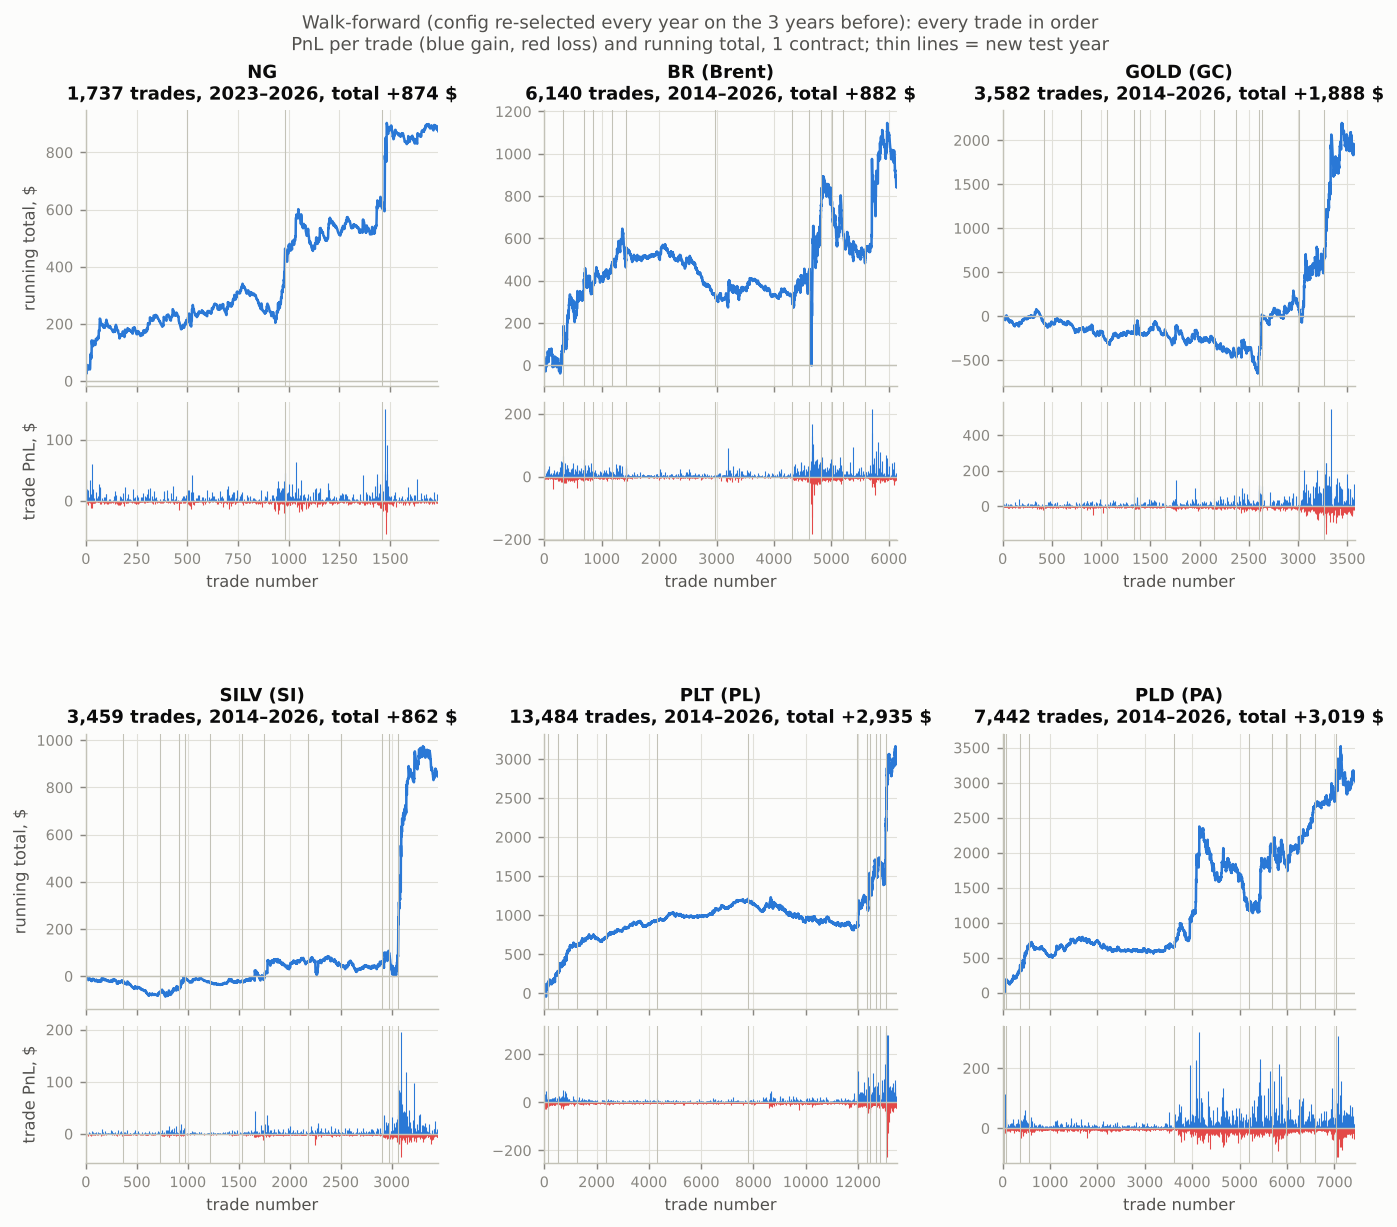

In [6]:
display(Image(filename=str(FIGS / "trade_outcomes_walk_forward.png")))

## Таблицы сделок

По каждому инструменту год за годом: заголовок года (конфигурация, годы обучения, число сделок и итог года), затем
все сделки года по порядку. Колонки: номер, сторона, время и контракт входа, цена входа, время и контракт выхода,
цена выхода, длительность в часах, результат в долларах и в тиках, исход и накопленный итог с начала walk-forward.

### NG

In [7]:
print(L.format_walk_forward_trades(led, "ng"))

== 2023: SMA21 / EMA66, pct k=10 eps=0.02%, exit=slope_flip · обучение 2020–2022 · сделок 501 · за год +209.00 $
  № сторона             вход контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1   Short 2023-01-03 09:05     NGF3      4.593 2023-01-04 14:20      NGF3       4.252  29.2 +34.10 +341.0 прибыль         +34.10
  2    Long 2023-01-04 16:15     NGF3      4.304 2023-01-05 09:15      NGF3       4.315  17.0  +1.10  +11.0 прибыль         +35.20
  3   Short 2023-01-05 10:05     NGF3      4.348 2023-01-05 10:45      NGF3       4.398   0.7  -5.00  -50.0  убыток         +30.20
  4    Long 2023-01-05 11:35     NGF3      4.404 2023-01-05 14:45      NGF3       4.368   3.2  -3.60  -36.0  убыток         +26.60
  5   Short 2023-01-05 17:50     NGF3      4.206 2023-01-06 17:00      NGF3       4.015  23.2 +19.10 +191.0 прибыль         +45.70
  6    Long 2023-01-06 18:35     NGF3      4.057 2023-01-06 22:50      NGF3       4.045   4.2  -1.20 

### BR (Brent)

In [8]:
print(L.format_walk_forward_trades(led, "br"))

== 2014: WMA43 / TMA83, atr k=10 eps=0.25 atr=14, exit=slope_flip · обучение 2011–2013 · сделок 331 · за год +66.80 $ · 1 с входом до начала года
  № сторона             вход  контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1   Short 2013-12-30 18:25 BRF4_2014     111.49 2014-01-06 17:05 BRF4_2014      107.75 166.7 +37.40 +374.0 прибыль         +37.40
  2    Long 2014-01-06 17:15 BRF4_2014     107.80 2014-01-06 20:20 BRF4_2014      107.24   3.1  -5.60  -56.0  убыток         +31.80
  3   Short 2014-01-06 22:25 BRF4_2014     106.96 2014-01-08 12:05 BRF4_2014      107.61  37.7  -6.50  -65.0  убыток         +25.30
  4    Long 2014-01-08 13:30 BRF4_2014     107.58 2014-01-08 21:25 BRF4_2014      107.56   7.9  -0.20   -2.0  убыток         +25.10
  5   Short 2014-01-08 21:45 BRF4_2014     107.50 2014-01-09 13:40 BRF4_2014      107.75  15.9  -2.50  -25.0  убыток         +22.60
  6    Long 2014-01-09 15:30 BRF4_2014     107.76 2014-01-09 2

### GOLD (GC)

In [9]:
print(L.format_walk_forward_trades(led, "gold"))

== 2014: EMA66 / SMA55, atr k=10 eps=0.25 atr=14, exit=slope_flip · обучение 2011–2013 · сделок 417 · за год -69.30 $
  № сторона             вход  контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1    Long 2014-01-06 10:05 GDH4_2014    1,245.5 2014-01-06 15:25 GDH4_2014     1,240.9   5.3  -4.60  -46.0  убыток          -4.60
  2   Short 2014-01-06 19:15 GDH4_2014    1,239.7 2014-01-06 20:45 GDH4_2014     1,242.8   1.5  -3.10  -31.0  убыток          -7.70
  3   Short 2014-01-06 23:40 GDH4_2014    1,242.4 2014-01-08 17:05 GDH4_2014     1,234.7  41.4  +7.70  +77.0 прибыль          +0.00
  4   Short 2014-01-08 22:10 GDH4_2014    1,227.6 2014-01-08 23:00 GDH4_2014     1,228.5   0.8  -0.90   -9.0  убыток          -0.90
  5    Long 2014-01-09 10:05 GDH4_2014    1,230.4 2014-01-09 20:30 GDH4_2014     1,228.7  10.4  -1.70  -17.0  убыток          -2.60
  6    Long 2014-01-10 13:15 GDH4_2014    1,236.2 2014-01-10 15:20 GDH4_2014     1,235.8  

### SILV (SI)

In [10]:
print(L.format_walk_forward_trades(led, "silv"))

== 2014: SMA59 / SMA48, pct k=10 eps=0.02%, exit=slope_flip · обучение 2011–2013 · сделок 369 · за год -27.90 $
  № сторона             вход  контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1    Long 2014-01-06 10:05 SVH4_2014      20.25 2014-01-06 17:00 SVH4_2014       20.10   6.9  -1.50  -15.0  убыток          -1.50
  2    Long 2014-01-06 23:25 SVH4_2014      20.29 2014-01-08 10:05 SVH4_2014       19.82  34.7  -4.70  -47.0  убыток          -6.20
  3   Short 2014-01-08 22:20 SVH4_2014      19.64 2014-01-08 23:15 SVH4_2014       19.61   0.9  +0.30   +3.0 прибыль          -5.90
  4    Long 2014-01-08 23:30 SVH4_2014      19.60 2014-01-09 18:25 SVH4_2014       19.62  18.9  +0.20   +2.0 прибыль          -5.70
  5    Long 2014-01-10 15:30 SVH4_2014      19.84 2014-01-10 16:45 SVH4_2014       19.89   1.2  +0.50   +5.0 прибыль          -5.20
  6    Long 2014-01-10 17:35 SVH4_2014      20.13 2014-01-13 12:55 SVH4_2014       20.12  67.3  

### PLT (PL)

In [11]:
print(L.format_walk_forward_trades(led, "plt"))

== 2014: WMA10 / EMA14, atr k=10 eps=0.25 atr=14, exit=reverse_cross · обучение 2011–2013 · сделок 124 · за год +70.50 $
  № сторона             вход  контракт цена входа            выход контракт  цена выхода часов PnL, $  тиков   исход накопленный, $
  1    Long 2014-01-06 10:05 PTH4_2014    1,400.2 2014-01-08 17:30 PTH4_2014     1,401.0  55.4  +0.80   +8.0 прибыль          +0.80
  2    Long 2014-01-09 17:10 PTH4_2014    1,411.0 2014-01-10 10:50 PTH4_2014     1,417.5  17.7  +6.50  +65.0 прибыль          +7.30
  3    Long 2014-01-10 17:55 PTH4_2014    1,419.1 2014-01-13 15:50 PTH4_2014     1,422.0  69.9  +2.90  +29.0 прибыль         +10.20
  4    Long 2014-01-17 11:35 PTH4_2014    1,430.0 2014-01-17 15:40 PTH4_2014     1,422.0   4.1  -8.00  -80.0  убыток          +2.20
  5    Long 2014-01-17 17:25 PTH4_2014    1,435.0 2014-01-20 10:10 PTH4_2014     1,440.0  64.8  +5.00  +50.0 прибыль          +7.20
  6    Long 2014-01-20 12:55 PTH4_2014    1,455.0 2014-01-20 15:45 PTH4_2014     1,455.

### PLD (PA)

In [12]:
print(L.format_walk_forward_trades(led, "pld"))

== 2014: SMA67 / EMA49, atr k=10 eps=0.25 atr=14, exit=slope_flip · обучение 2011–2013 · сделок 1 · за год -4.86 $ · 1 с входом до начала года
 № сторона             вход  контракт цена входа            выход контракт  цена выхода  часов PnL, $  тиков  исход накопленный, $
 1   Short 2013-11-18 17:00 PDZ3_2013     739.11 2014-03-06 18:05 PDH4_2014      777.10 2593.1  -4.86 -486.0 убыток          -4.86

== 2015: TMA26 / EMA5, atr k=10 eps=0.25 atr=14, exit=slope_flip · обучение 2012–2014 · сделок 32 · за год +13.39 $ · 1 с входом до начала года
 № сторона             вход  контракт цена входа            выход контракт  цена выхода  часов PnL, $    тиков   исход накопленный, $
 2    Long 2014-12-15 13:15 PDH5_2015     810.08 2015-03-02 18:25 PDH5_2015      813.00 1853.2  +2.92   +292.0 прибыль          -1.94
 3   Short 2015-03-16 13:40 PDH5_2015     787.12 2015-03-16 14:50 PDH5_2015      787.98    1.2  -0.86    -86.0  убыток          -2.80
 4   Short 2015-04-22 23:35 PDM5_2015     756.85